# Temperature Regression + Kriging (Standard Layers)

This notebook reproduces the regression-kriging workflow using temperature-related standard layers: NDVI, impervious surface, NDBI, and optional tree canopy.

In [41]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        has_data = (candidate / "data" / "spatial" / "grid_rectangles.geojson").exists()
        has_src = (candidate / "src").exists()
        if has_data and has_src:
            return candidate
    raise FileNotFoundError("Could not find project root from current notebook path.")


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.time_series.series_aligner import align_sensor_series
from src.kriging.ridge_regression import train_ridge, ridge_predict
from src.kriging.variogram_training import fit_variogram_model, plot_variogram_fit, ordinary_kriging_predict

print(f"PROJECT_ROOT: {PROJECT_ROOT}")

PROJECT_ROOT: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis


In [ ]:
#Open the layers
# Load extracted temperature layers
LAYER_DIR = DATA_DIR / "kriging_satellite" / "layers"

required_layer_paths = {
    "ndvi": LAYER_DIR / "ndvi_grid.geojson",
    "impervious": LAYER_DIR / "nlcd_impervious_grid.geojson",
    "ndbi": LAYER_DIR / "ndbi_grid.geojson",
    "road_density": LAYER_DIR / "road_density_grid.geojson",
    # "emissions": LAYER_DIR / "nei_emissions_grid.geojson",
    # "population_density": LAYER_DIR / "population_density_grid.geojson",
}
optional_layer_paths = {
    "tree_canopy": LAYER_DIR / "tree_canopy_grid.geojson",
}

missing_required = [name for name, path in required_layer_paths.items() if not path.exists()]
if missing_required:
    raise FileNotFoundError(f"Missing required temperature layers: {missing_required}")

layer_gdfs = {name: gpd.read_file(path) for name, path in required_layer_paths.items()}

available_optional = {}
for name, path in optional_layer_paths.items():
    if path.exists():
        available_optional[name] = path
        layer_gdfs[name] = gpd.read_file(path)

print("Loaded required layers:", list(required_layer_paths.keys()))
print("Loaded optional layers:", list(available_optional.keys()))

Loaded required layers: ['ndvi', 'impervious', 'ndbi', 'road_density']
Loaded optional layers: []


In [43]:
# Load Boston sensor series and compute mean temperature between 15:00 and 16:00
SENSORS_DIR = DATA_DIR / "sensors"
sensor_csvs = {
    "Boston Carter Field": SENSORS_DIR / "boston_carter_field" / "boston_carter_field.csv",
    "Boston Gainsborough Parking Garage": SENSORS_DIR / "boston_gainsborough_parking" / "boston_gainsborough_parking.csv",
    "Boston Robinson Hall": SENSORS_DIR / "boston_robinson_hall" / "boston_robinson_hall.csv",
    "Boston West Village B": SENSORS_DIR / "boston_west_village_b" / "boston_west_village_b.csv",
    "Boston World Series Way": SENSORS_DIR / "boston_world_series_way" / "boston_world_series_way.csv",
}

missing_csvs = [name for name, path in sensor_csvs.items() if not path.exists()]
if missing_csvs:
    raise FileNotFoundError(f"Missing sensor CSV files for: {missing_csvs}")

all_sensors = {name: pd.read_csv(path) for name, path in sensor_csvs.items()}

aligned_df, lag_info = align_sensor_series(
    sensor_dataframes=all_sensors,
    variable_name="temperature",
    time_column="timestamp",
    sampling_interval="1min",
    timestamp_tolerance="15min",
)

initial_temp = "15:00"
final_temp = "16:00"
aligned_between = aligned_df.between_time(initial_temp, final_temp)
if aligned_between.empty:
    raise ValueError("No aligned temperature data between 15:00 and 16:00.")

measurements_at_timestamp = aligned_between.mean(axis=0)

sensor_locations = pd.read_json(DATA_DIR / "spatial" / "sensor_locations.json")
sensor_names = list(sensor_csvs.keys())

sensor_temperatures = measurements_at_timestamp.reindex(sensor_names)
if sensor_temperatures.isna().any():
    missing = sensor_temperatures[sensor_temperatures.isna()].index.tolist()
    raise ValueError(f"Missing temperatures for sensors: {missing}")

sensor_locations = sensor_locations[sensor_locations["sensor_name"].isin(sensor_names)].copy()
sensor_locations = sensor_locations.set_index("sensor_name").loc[sensor_names].reset_index()
sensor_locations["temperature"] = sensor_temperatures.values

gdf_sensors = gpd.GeoDataFrame(
    sensor_locations,
    geometry=gpd.points_from_xy(sensor_locations["longitude"], sensor_locations["latitude"]),
    crs="EPSG:4326",
)

print(f"Aligned rows total: {len(aligned_df)}")
print(f"Aligned rows between {initial_temp} and {final_temp}: {len(aligned_between)}")
gdf_sensors[["sensor_name", "temperature", "geometry"]]

Aligned rows total: 39886
Aligned rows between 15:00 and 16:00: 638


,sensor_name,temperature,geometry
0,Boston Carter Field,26.214514,POINT (-71.08435 42.33925)
1,Boston Gainsborough Parking Garage,28.377312,POINT (-71.08508 42.34039)
2,Boston Robinson Hall,28.198644,POINT (-71.08652 42.33919)
3,Boston West Village B,22.676928,POINT (-71.09238 42.33765)
4,Boston World Series Way,24.120776,POINT (-71.0899 42.33874)


In [44]:
# Merge layer predictors onto one grid and map sensors to cells
def _ensure_grid_id(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    if "grid_id" in gdf.columns:
        return gdf.copy()
    if "id" in gdf.columns:
        out = gdf.copy()
        out = out.rename(columns={"id": "grid_id"})
        return out
    return gdf.reset_index(drop=False).rename(columns={"index": "grid_id"})


def _pick_feature_col(gdf: gpd.GeoDataFrame, candidates: list[str], feature_name: str) -> str:
    for col in candidates:
        if col in gdf.columns:
            return col
    raise ValueError(
        f"No usable column found for '{feature_name}'. Tried {candidates}. "
        f"Available columns: {list(gdf.columns)}"
    )


base = _ensure_grid_id(layer_gdfs["ndvi"])
base_crs = base.crs

feature_specs = [
    ("ndvi", ["ndvi", "ndvi_mean", "ndvi_median"], "ndvi"),
    ("impervious", ["impervious", "nlcd_impervious", "impervious_surface"], "impervious"),
    ("ndbi", ["ndbi", "ndbi_mean", "ndbi_median"], "ndbi"),
    ("road_density", ["road_density_km_km2", "road_density"], "road_density"),
    # ("emissions", ["emissions_tpy", "total_emissions_tpy", "emissions"], "emissions"),
    # ("population_density", ["population_density_km2", "population_density"], "population_density"),
]
if "tree_canopy" in layer_gdfs:
    feature_specs.append(("tree_canopy", ["tree_canopy", "tcc", "canopy"], "tree_canopy"))

grid_features = base[["grid_id", "geometry"]].copy()
predictor_cols = []

for layer_name, candidates, out_name in feature_specs:
    layer = _ensure_grid_id(layer_gdfs[layer_name])
    if layer.crs != base_crs:
        layer = layer.to_crs(base_crs)
    selected_col = _pick_feature_col(layer, candidates, out_name)
    predictor_cols.append(out_name)
    grid_features = grid_features.merge(
        layer[["grid_id", selected_col]].rename(columns={selected_col: out_name}),
        on="grid_id",
        how="left",
    )

sensors_proj = gdf_sensors.to_crs(base_crs)
sensor_with_grid = gpd.sjoin(
    sensors_proj,
    grid_features,
    how="left",
    predicate="within",
)

# Fallback for unmatched points: nearest grid cell
unmatched_mask = sensor_with_grid["grid_id"].isna()
if unmatched_mask.any():
    nearest = gpd.sjoin_nearest(
        sensors_proj.loc[unmatched_mask].copy(),
        grid_features,
        how="left",
        distance_col="distance_to_grid",
    )
    fill_cols = ["grid_id"] + predictor_cols
    sensor_with_grid.loc[unmatched_mask, fill_cols] = nearest[fill_cols].to_numpy()

# Fallback for NaN predictors: nearest valid cell per predictor
for col in predictor_cols:
    nan_mask = sensor_with_grid[col].isna()
    if not nan_mask.any():
        continue

    valid_cells = grid_features[["geometry", col]].dropna(subset=[col]).copy()
    if valid_cells.empty:
        continue

    nearest_valid = gpd.sjoin_nearest(
        sensors_proj.loc[nan_mask].copy(),
        valid_cells,
        how="left",
        distance_col=f"distance_to_{col}",
    )
    sensor_with_grid.loc[nan_mask, col] = nearest_valid[col].to_numpy()

sensor_cell_df = pd.DataFrame(
    {
        "sensor_name": sensor_with_grid["sensor_name"],
        "temperature": sensor_with_grid["temperature"],
        "grid_id": sensor_with_grid["grid_id"],
        **{c: sensor_with_grid[c] for c in predictor_cols},
    }
).drop_duplicates(subset=["sensor_name"]).reset_index(drop=True)

print("Predictors used:", predictor_cols)
sensor_cell_df

Predictors used: ['ndvi', 'impervious', 'ndbi', 'road_density']


,sensor_name,temperature,grid_id,ndvi,impervious,ndbi,road_density
0,Boston Carter Field,26.214514,705,0.201778,79.098096,-0.023662,11.000051
1,Boston Gainsborough Parking Garage,28.377312,678,0.035911,86.844909,-0.028702,30.825609
2,Boston Robinson Hall,28.198644,615,0.184991,81.500348,-0.145354,23.648700
3,Boston West Village B,22.676928,401,0.233308,84.536850,-0.194531,24.167291
4,Boston World Series Way,24.120776,494,0.130808,86.319335,-0.084936,22.433620


In [45]:
# PCA on full satellite grid → sat_pc1, sat_pc2
target_col = "temperature"

for frame in [sensor_cell_df, grid_features]:
    frame["road_density_log1p"] = np.log1p(frame["road_density"].clip(lower=0.0))
    # frame["emissions_log1p"] = np.log1p(frame["emissions"].clip(lower=0.0))
    # frame["population_density_log1p"] = np.log1p(frame["population_density"].clip(lower=0.0))

predictor_cols_pca = ['ndvi', 'ndbi', 'impervious', 'road_density_log1p']

for col in predictor_cols_pca:
    if grid_features[col].isna().any():
        grid_features[col] = grid_features[col].fillna(grid_features[col].median())

scaler = StandardScaler()
pca = PCA(n_components=2)
X_grid_scaled = scaler.fit_transform(grid_features[predictor_cols_pca])
X_grid_pca = pca.fit_transform(X_grid_scaled)
grid_features["sat_pc1"] = X_grid_pca[:, 0]
grid_features["sat_pc2"] = X_grid_pca[:, 1]

print(f"SAT PCA — PC1: {pca.explained_variance_ratio_[0]:.3f}, PC2: {pca.explained_variance_ratio_[1]:.3f}, total: {pca.explained_variance_ratio_.sum():.3f}")
print("\nPCA loadings:")
for i, pc in enumerate(pca.components_):
    print(f"  PC{i+1}:", "  ".join(f"{feat}={val:+.3f}" for feat, val in zip(predictor_cols_pca, pc)))


X_sensor_scaled = scaler.transform(sensor_cell_df[predictor_cols_pca].fillna(0))
X_sensor_pca = pca.transform(X_sensor_scaled)
sensor_cell_df["sat_pc1"] = X_sensor_pca[:, 0]
sensor_cell_df["sat_pc2"] = X_sensor_pca[:, 1]

predictor_cols = ["sat_pc1", "sat_pc2"]

train_df = sensor_cell_df[[target_col] + predictor_cols].dropna().copy()
if train_df.empty:
    raise ValueError("No sensor rows available for training after dropping NaNs.")

ridge_model = train_ridge(
    X=train_df[predictor_cols].to_numpy(dtype=float),
    y=train_df[target_col],
    alpha=1.0,
    fit_intercept=True,
)

print("Ridge trained (temperature)")
print("n_samples:", ridge_model["n_samples"])
print("score_r2:", ridge_model["score_r2"])
for name, coef in zip(predictor_cols, ridge_model["coefficients"]):
    print(f"  {name}: {coef:.6f}")
print("intercept:", ridge_model["intercept"])


SAT PCA — PC1: 0.674, PC2: 0.242, total: 0.916

PCA loadings:
  PC1: ndvi=+0.587  ndbi=-0.572  impervious=-0.556  road_density_log1p=-0.137
  PC2: ndvi=+0.087  ndbi=-0.078  impervious=-0.073  road_density_log1p=+0.990
Ridge trained (temperature)
n_samples: 5
score_r2: 0.28292629039025174
  sat_pc1: -1.084189
  sat_pc2: 0.013042
intercept: 25.344200866842783


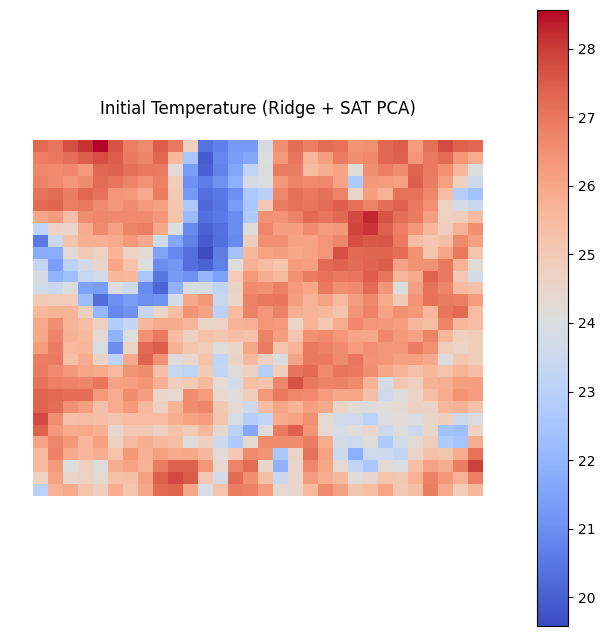

,grid_id,geometry,ndvi,impervious,ndbi,road_density,road_density_log1p,sat_pc1,sat_pc2,predicted_temperature_ridge
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",0.325637,59.043725,-0.207903,NaN,3.186149,2.146430,0.360612,23.021769
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",0.217034,74.126761,-0.159759,24.844960,3.252116,0.620153,0.241238,24.674984
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",0.160051,76.528328,-0.127417,37.069438,3.639412,-0.134354,0.685200,25.498802
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",0.156749,77.903810,-0.112085,14.902990,2.766507,-0.153127,-0.557634,25.502947
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",0.128992,79.078385,-0.074170,17.275134,2.905541,-0.691640,-0.435060,26.088395


In [46]:
# Predict using PCA components
X_grid = grid_features[predictor_cols].to_numpy(dtype=float)
grid_features["predicted_temperature_ridge"] = ridge_predict(ridge_model, X_grid)

initial_temperature_map = gpd.GeoDataFrame(grid_features, geometry="geometry", crs=base_crs)

fig, ax = plt.subplots(figsize=(8, 8))
initial_temperature_map.plot(column="predicted_temperature_ridge", cmap="coolwarm", legend=True, ax=ax)
ax.set_axis_off()
ax.set_title("Initial Temperature (Ridge + SAT PCA)")
plt.show()
initial_temperature_map.head()


In [47]:
# Compute sensor residuals
sensor_model_df = sensor_cell_df[["sensor_name", "temperature"] + predictor_cols].dropna().copy()
if sensor_model_df.empty:
    raise ValueError("No sensor rows available for residual computation.")

sensor_model_df["ridge_pred_at_sensor"] = ridge_predict(
    ridge_model,
    sensor_model_df[predictor_cols].to_numpy(dtype=float),
)
sensor_model_df["residual"] = sensor_model_df["temperature"] - sensor_model_df["ridge_pred_at_sensor"]

sensors_proj = gdf_sensors.to_crs(initial_temperature_map.crs).copy()
sensors_proj["x"] = sensors_proj.geometry.x
sensors_proj["y"] = sensors_proj.geometry.y

sensor_residuals_df = sensor_model_df.merge(
    sensors_proj[["sensor_name", "x", "y"]],
    on="sensor_name",
    how="left",
)
sensor_residuals_df


,sensor_name,temperature,sat_pc1,sat_pc2,ridge_pred_at_sensor,residual,x,y
0,Boston Carter Field,26.214514,-0.586172,-1.012829,25.966513,0.248001,234252.312622,898834.637669
1,Boston Gainsborough Parking Garage,28.377312,-1.969148,0.173885,27.481397,0.895915,234191.453996,898960.969606
2,Boston Robinson Hall,28.198644,0.089828,0.100597,25.248122,2.950522,234073.213353,898826.532851
3,Boston West Village B,22.676928,0.680734,0.214417,24.608953,-1.932025,233591.199929,898653.278770
4,Boston World Series Way,24.120776,-0.867331,-0.104460,26.283189,-2.162413,233795.319059,898775.220621


Residual variogram model:
{'model': 'gaussian', 'nugget': 0.0, 'sill': 6.535525892932782, 'range': 198.4449346201937, 'score_mse': 14.756015162081571, 'lag_centers': [128.53819628807997, 214.23032714679997, 299.92245800551996, 471.30671972295994, 642.6909814403999], 'experimental_semivariance': [0.20989587917532057, 1.929684517965283, 13.071051785865563, 6.500454820779619, 3.1874391442285654], 'fitted_semivariance': [2.2394492512463304, 4.497799997939061, 5.869859885250597, 6.512320537350218, 6.535343894535804]}


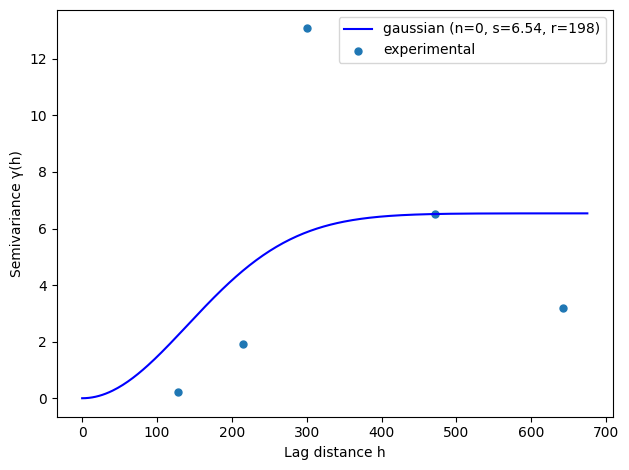

In [48]:
# Fit variogram model on residuals
res_points = list(zip(sensor_residuals_df["x"].to_list(), sensor_residuals_df["y"].to_list()))
res_values = sensor_residuals_df["residual"].to_list()

residual_variogram_model = fit_variogram_model(
    points=res_points,
    values=res_values,
)

print("Residual variogram model:")
print(residual_variogram_model)
plot_variogram_fit(residual_variogram_model)

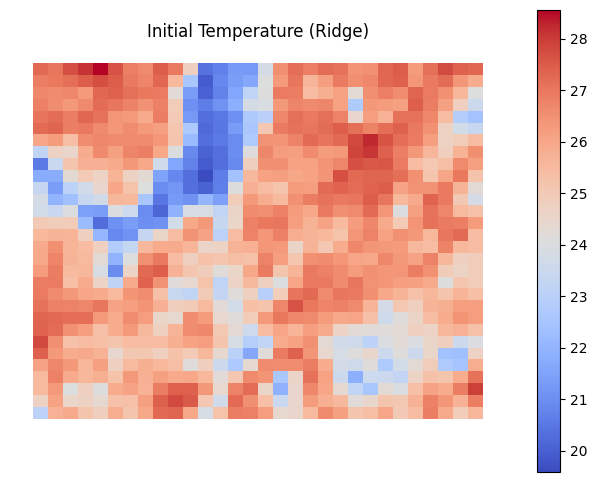

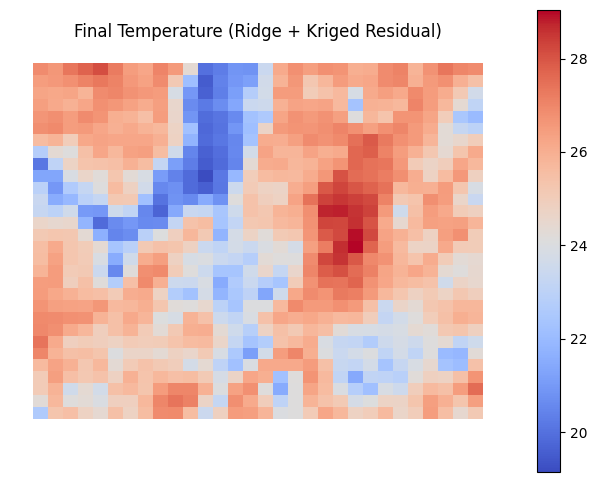

Saved initial temperature figure to: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_satellite/layers/temperature_ridge_initial_map.png
Saved final temperature figure to: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_satellite/layers/temperature_ridge_final_map.png


,grid_id,geometry,ndvi,impervious,ndbi,road_density,road_density_log1p,sat_pc1,sat_pc2,predicted_temperature_ridge,estimated_residual,final_temperature
0,0,"POLYGON ((232762.527 898058.685, 232826.045 89...",0.325637,59.043725,-0.207903,NaN,3.186149,2.146430,0.360612,23.021769,-0.413879,22.607890
1,1,"POLYGON ((232762.527 898108.712, 232826.045 89...",0.217034,74.126761,-0.159759,24.844960,3.252116,0.620153,0.241238,24.674984,-0.413879,24.261105
2,2,"POLYGON ((232762.527 898158.739, 232826.045 89...",0.160051,76.528328,-0.127417,37.069438,3.639412,-0.134354,0.685200,25.498802,-0.413879,25.084924
3,3,"POLYGON ((232762.527 898208.766, 232826.045 89...",0.156749,77.903810,-0.112085,14.902990,2.766507,-0.153127,-0.557634,25.502947,-0.413879,25.089068
4,4,"POLYGON ((232762.527 898258.793, 232826.045 89...",0.128992,79.078385,-0.074170,17.275134,2.905541,-0.691640,-0.435060,26.088395,-0.413879,25.674516


In [49]:
# Krige residuals and produce final temperature map
query_points = [(geom.centroid.x, geom.centroid.y) for geom in initial_temperature_map.geometry]
res_points = list(zip(sensor_residuals_df["x"].to_list(), sensor_residuals_df["y"].to_list()))
res_values = sensor_residuals_df["residual"].to_list()

estimated_residuals = ordinary_kriging_predict(
    points=res_points,
    values=res_values,
    fit=residual_variogram_model,
    query_points=query_points,
)

final_temperature_map = initial_temperature_map.copy()
final_temperature_map["estimated_residual"] = estimated_residuals
final_temperature_map["final_temperature"] = (
    final_temperature_map["predicted_temperature_ridge"] + final_temperature_map["estimated_residual"]
)

TEMP_INITIAL_FIG_PATH = LAYER_DIR / "temperature_ridge_initial_map.png"
TEMP_FINAL_FIG_PATH = LAYER_DIR / "temperature_ridge_final_map.png"
TEMP_INITIAL_FIG_PATH.parent.mkdir(parents=True, exist_ok=True)

fig_initial, ax_initial = plt.subplots(figsize=(8, 6))
initial_temperature_map.plot(column="predicted_temperature_ridge", cmap="coolwarm", legend=True, ax=ax_initial)
ax_initial.set_axis_off()
ax_initial.set_title("Initial Temperature (Ridge)")
fig_initial.savefig(TEMP_INITIAL_FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

fig_final, ax_final = plt.subplots(figsize=(8, 6))
final_temperature_map.plot(column="final_temperature", cmap="coolwarm", legend=True, ax=ax_final)
ax_final.set_axis_off()
ax_final.set_title("Final Temperature (Ridge + Kriged Residual)")
fig_final.savefig(TEMP_FINAL_FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved initial temperature figure to: {TEMP_INITIAL_FIG_PATH}")
print(f"Saved final temperature figure to: {TEMP_FINAL_FIG_PATH}")

final_temperature_map.head()

In [50]:
# Save final output
TEMP_OUTPUT_PATH = LAYER_DIR / "temperature_ridge_kriging_grid.geojson"
TEMP_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
final_temperature_map.to_file(TEMP_OUTPUT_PATH, driver="GeoJSON")
print(f"Saved final temperature map to: {TEMP_OUTPUT_PATH}")

Saved final temperature map to: /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/kriging_satellite/layers/temperature_ridge_kriging_grid.geojson
